In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    RepeatVector,
    Attention,
    Concatenate
)

from tensorflow.keras.models import Model, load_model

from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import mean_absolute_error, mean_squared_error

from pathlib import Path

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.22.0-rc0


In [2]:
BASE_DIR = Path.cwd().parent

DATA_PATH = BASE_DIR / "data" / "rossmann" / "train.csv"

MODEL_DIR = BASE_DIR / "models"

OUTPUT_DIR = BASE_DIR / "outputs"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LOOKBACK = 30

HORIZON = 14

In [3]:
df = pd.read_csv(DATA_PATH)

# Select Store 1
store_data = df[df["Store"] == 1].copy()

# Convert date
store_data["Date"] = pd.to_datetime(store_data["Date"])

# Sort by date
store_data = store_data.sort_values("Date")

# Set date as index
sales = store_data.set_index("Date")["Sales"]

# Daily frequency
sales = sales.asfreq("D")

# Remove missing values
sales = sales.dropna()

print(sales.head())

print("Total records:", len(sales))

Date
2013-01-01       0
2013-01-02    5530
2013-01-03    4327
2013-01-04    4486
2013-01-05    4997
Freq: D, Name: Sales, dtype: int64
Total records: 942


C:\Users\SUBHOJIT\AppData\Local\Temp\ipykernel_16624\3394094158.py:1: DtypeWarning: Columns (7: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


In [4]:
sales_values = sales.values.astype("float32")

# 80% training data
split_index = int(len(sales_values) * 0.80)

train_values = sales_values[:split_index]

# Scale using training maximum
scaler = train_values.max()

scaled_sales = sales_values / scaler

print("Training records:", len(train_values))

print("Testing records:", len(sales_values) - split_index)

print("Scaler:", scaler)

Training records: 753
Testing records: 189
Scaler: 9528.0


In [5]:
X = []
y = []

dates = sales.index

for i in range(len(scaled_sales) - LOOKBACK - HORIZON + 1):

    # Input sequence
    X.append(
        scaled_sales[i:i + LOOKBACK]
    )

    # Output sequence
    y.append(
        scaled_sales[i + LOOKBACK:i + LOOKBACK + HORIZON]
    )

X = np.array(X)

y = np.array(y)

# Add feature dimension
X = X.reshape(-1, LOOKBACK, 1)

y = y.reshape(-1, HORIZON, 1)

print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (899, 30, 1)
y shape: (899, 14, 1)


In [6]:
sequence_end = np.arange(
    LOOKBACK + HORIZON - 1,
    len(scaled_sales)
)

train_mask = sequence_end < split_index

test_mask = sequence_end >= split_index

X_train = X[train_mask]

y_train = y[train_mask]

X_test = X[test_mask]

y_test = y[test_mask]

print("X_train:", X_train.shape)

print("y_train:", y_train.shape)

print("X_test:", X_test.shape)

print("y_test:", y_test.shape)

X_train: (710, 30, 1)
y_train: (710, 14, 1)
X_test: (189, 30, 1)
y_test: (189, 14, 1)


In [7]:
# -------------------------
# ENCODER
# -------------------------

encoder_input = Input(shape=(LOOKBACK, 1))

encoder_lstm = LSTM(
    32,
    return_sequences=True,
    return_state=True
)

encoder_output, state_h, state_c = encoder_lstm(
    encoder_input
)


# -------------------------
# DECODER
# -------------------------

decoder_input = RepeatVector(HORIZON)(state_h)

decoder_lstm = LSTM(
    32,
    return_sequences=True
)

decoder_output = decoder_lstm(
    decoder_input,
    initial_state=[state_h, state_c]
)


# -------------------------
# ATTENTION
# -------------------------

attention_layer = Attention()

context, attention_weights = attention_layer(
    [decoder_output, encoder_output],
    return_attention_scores=True
)


# -------------------------
# COMBINE OUTPUTS
# -------------------------

combined = Concatenate(axis=-1)(
    [decoder_output, context]
)


# -------------------------
# PREDICTION
# -------------------------

output = Dense(1)(combined)


# -------------------------
# COMPLETE MODEL
# -------------------------

model = Model(
    inputs=encoder_input,
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 30, 32),  │      4,352 │ input_layer[0][0] │
│                     │ (None, 32),       │            │                   │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 14, 32)    │          0 │ lstm[0][1]        │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 14, 32)    │      8,320 │ repeat_vector[0]… │
│                     │                   │            │ lstm[0][1],       │
│                     │                   │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, 14, 32),  │          0 │ lstm_1[0][0],     │
│ (Attention)         │ (None, 14, 30)]   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 14, 64)    │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 14, 1)     │         65 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,737 (49.75 KB)

 Trainable params: 12,737 (49.75 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop]
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 109ms/step - loss: 0.0923 - mae: 0.2441 - val_loss: 0.0814 - val_mae: 0.2218
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0463 - mae: 0.1684 - val_loss: 0.0751 - val_mae: 0.2181
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0438 - mae: 0.1547 - val_loss: 0.0754 - val_mae: 0.2237
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0435 - mae: 0.1552 - val_loss: 0.0748 - val_mae: 0.2218
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0432 - mae: 0.1545 - val_loss: 0.0746 - val_mae: 0.2218
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0431 - mae: 0.1539 - val_loss: 0.0748 - val_mae: 0.2231
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0430 - mae: 0.1537 - val_loss: 0.0751 - val_mae: 0.2245
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0430 - mae: 0.1536 - val_loss: 0.0753 - val_mae: 0.2256
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.04

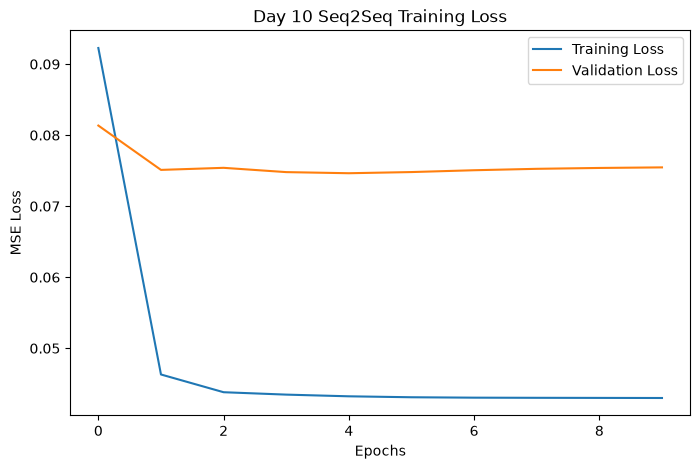

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Day 10 Seq2Seq Training Loss")

plt.xlabel("Epochs")

plt.ylabel("MSE Loss")

plt.legend()

plt.show()

In [10]:
predictions = model.predict(X_test)

# Convert to original sales scale
predictions = predictions * scaler

actual = y_test * scaler

print("Predictions shape:", predictions.shape)

print("Actual shape:", actual.shape)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Predictions shape: (189, 14, 1)
Actual shape: (189, 14, 1)


In [11]:
mae = mean_absolute_error(
    actual.flatten(),
    predictions.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        actual.flatten(),
        predictions.flatten()
    )
)

print("Day 10 MAE:", mae)

print("Day 10 RMSE:", rmse)

Day 10 MAE: 1404.0977783203125
Day 10 RMSE: 1874.7559841216669


In [12]:
# Create attention model
attention_model = Model(
    inputs=encoder_input,
    outputs=attention_weights
)

# Extract attention weights
weights = attention_model.predict(
    X_test[:1]
)

print("Attention weights shape:", weights.shape)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
Attention weights shape: (1, 14, 30)


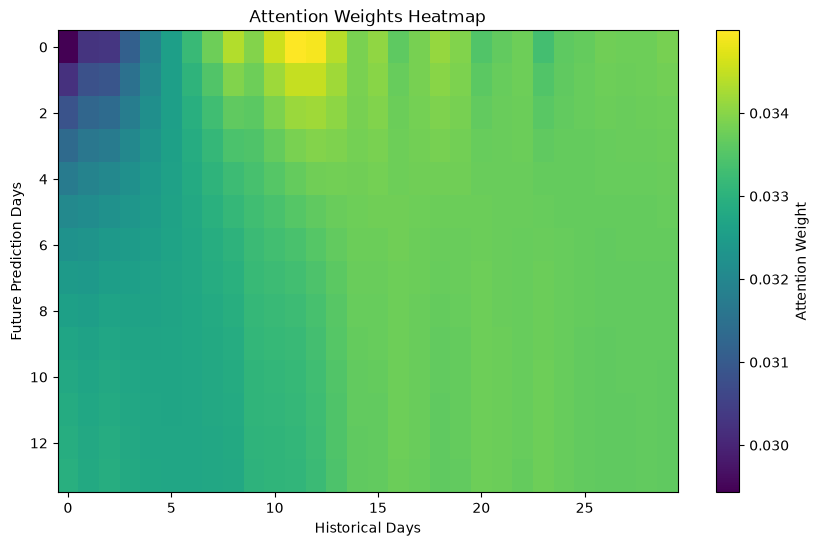

In [13]:
plt.figure(figsize=(10, 6))

plt.imshow(
    weights[0],
    aspect="auto",
    cmap="viridis"
)

plt.colorbar(label="Attention Weight")

plt.xlabel("Historical Days")

plt.ylabel("Future Prediction Days")

plt.title("Attention Weights Heatmap")

plt.show()

In [14]:
day9_model = load_model(
    MODEL_DIR / "demand_lstm.keras"
)

print("Day 9 LSTM loaded successfully!")

Day 9 LSTM loaded successfully!


In [ ]:
day9_predictions = []

for i in range(len(X_test)):

    current = X_test[i].flatten().copy()

    forecast = []

    for day in range(HORIZON):

        next_value = day9_model.predict(
            current.reshape(1, LOOKBACK, 1),
            verbose=0
        )[0, 0]

        forecast.append(next_value)

        current = np.append(
            current[1:],
            next_value
        )

    day9_predictions.append(forecast)


day9_predictions = np.array(day9_predictions)

day9_predictions = day9_predictions.reshape(
    -1, HORIZON, 1
)

day9_predictions = day9_predictions * scaler

print("Day 9 predictions:", day9_predictions.shape)

In [ ]:
day9_mae = mean_absolute_error(
    actual.flatten(),
    day9_predictions.flatten()
)

day9_rmse = np.sqrt(
    mean_squared_error(
        actual.flatten(),
        day9_predictions.flatten()
    )
)

comparison = pd.DataFrame({
    "Model": ["Day 9 LSTM", "Day 10 Seq2Seq Attention"],
    "MAE": [day9_mae, mae],
    "RMSE": [day9_rmse, rmse]
})

print(comparison)

In [ ]:
# Get the latest 30 days
last_30_days = scaled_sales[-LOOKBACK:]

# Reshape input
future_input = last_30_days.reshape(
    1, LOOKBACK, 1
)

# Predict next 14 days
future_predictions = model.predict(
    future_input
)

# Convert back to original scale
future_predictions = future_predictions.flatten() * scaler

print("Future sales predictions:")

print(future_predictions)

In [ ]:
future_dates = pd.date_range(
    start=sales.index[-1] + pd.Timedelta(days=1),
    periods=HORIZON,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Sales": future_predictions
})

print(forecast_df)

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    sales.index[-30:],
    sales.values[-30:],
    label="Historical Sales"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["Predicted_Sales"],
    marker="o",
    label="Predicted Sales"
)

plt.title("14-Day Sales Forecast")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [ ]:
# Save trained model
model.save(
    MODEL_DIR / "demand_seq2seq_attention.keras"
)

# Save forecast
forecast_df.to_csv(
    OUTPUT_DIR / "demand_forecast_14_days.csv",
    index=False
)

# Save comparison
comparison.to_csv(
    OUTPUT_DIR / "day9_day10_comparison.csv",
    index=False
)

print("Day 10 files saved successfully!")